# 06 · Reducción de dimensionalidad (PCA) y visualización de los segmentos

Cada cliente es un punto en un espacio de **28 dimensiones** (las 28 features del modelo), y ahí es donde K-Means ha encontrado los 7 segmentos. No podemos dibujar 28 dimensiones, así que usamos **PCA** para resumirlas en unas pocas que sí podamos mirar.

Lo que pide el reto:

1. Aplicar PCA sobre las features.
2. Indicar la **varianza explicada** por cada componente y la acumulada.
3. **Gráfico 2D** (y opcionalmente 3D) coloreado por cluster.
4. Analizar qué **variables originales pesan más** en cada componente.

Y como entregables: la interpretación de las componentes y una **valoración**: ¿los clusters son visualmente separables?

Como en el resto de notebooks, lo que afirmamos en el texto va respaldado por una tabla o un `assert`.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

from src import config, clean, clustering
from src import pipeline as pl
from src.segmentos import SEGMENTOS

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
FIG = config.FIG_DIR  # todas las figuras se guardan en outputs/figuras
FIG.mkdir(parents=True, exist_ok=True)

K = config.K_FINAL
COLORES = config.SEGMENT_COLORS  # los mismos colores de segmento que el notebook 04 y el dashboard
GRIS = config.BASE_GRAY

## 1. Qué es PCA y por qué lo usamos así

PCA busca las **direcciones en las que los clientes se diferencian más** (las que tienen más varianza) y las ordena: la componente 1 (PC1) es la dirección con más variación, la PC2 la siguiente (perpendicular a la primera), etc. Cada componente es una **mezcla de las variables originales**, y los pesos de esa mezcla (las **cargas** o *loadings*) nos dicen qué significa.

Tres decisiones, y por qué:

- **Aplicamos PCA sobre la misma matriz `X` que usó K-Means**, sin reescalarla. Queremos ver el espacio tal y como lo "vio" K-Means: si cambiáramos las escalas, el dibujo mostraría una geometría distinta de la que formó los segmentos.
- **PCA es solo para mirar, no para volver a segmentar.** Los segmentos son los del reto 3 (K-Means con las 28 features). Reentrenar sobre 2 o 3 componentes perdería buena parte de la información (lo medimos abajo) y nos daría segmentos distintos de los que ya hemos interpretado en el reto 4.
- **Calculamos PCA con todos los clientes**, pero en los gráficos de puntos dibujamos una **muestra fija de 20.000** (la misma de los notebooks 03 y 05). Con 173.456 puntos el gráfico sería una mancha y no se vería nada.

## 2. Los datos y los segmentos

La misma tabla de clientes, el mismo pipeline (28 features) y los mismos segmentos que en el reto 3, con los nombres del reto 4.

In [2]:
if config.CLIENTS_PKL.exists():
    clientes = clean.load_clients()
else:
    clientes = clean.build_client_table(clean.load_raw())

prep = pl.build_preprocessor()
X = prep.fit_transform(clientes)
nombres = list(prep.get_feature_names_out())

modelo = pl.build_pipeline(K).fit(clientes)
seg = clustering.relabel_by_size(modelo.named_steps["kmeans"].labels_)
assert np.bincount(seg).tolist() == [41811, 31769, 31611, 27575, 15660, 15327, 9703]  # los del reto 3
if config.LABELS_FINAL.exists():
    assert (clustering.load_labels().reindex(clientes.index).values == seg).all()

SEG = [SEGMENTOS[i]["nombre"] for i in range(K)]
print("X:", X.shape)
pd.DataFrame({"segmento": SEG, "clientes": np.bincount(seg)})

X: (173456, 28)


,segmento,clientes
0,Coche en garantía,41811
1,Recién llegados,31769
2,Coche veterano,31611
3,Electrificados,27575
4,Desconectados,15660
5,Multivehículo,15327
6,Zonas premium,9703


Antes de aplicar PCA, una cosa importante que condiciona todo lo que viene: **no todas las features tienen el mismo peso en `X`**. Las numéricas están escaladas (varianza 1 cada una) y las binarias y one-hot valen 0 o 1, con varianzas mucho menores. PCA busca varianza, así que veremos que las componentes las dominan las numéricas. Y es lo mismo que le pasa a K-Means, porque mide distancias en este mismo espacio.

In [3]:
varianza = pd.Series(X.var(axis=0), index=nombres)
num = pl.LOG_COLS + pl.NUM_COLS
bloques = pd.DataFrame({
    "columnas": [len(num), len(nombres) - len(num)],
    "varianza total": [varianza[num].sum(), varianza.drop(num).sum()],
}, index=["numéricas (escaladas)", "binarias y one-hot"])
bloques["% de la varianza"] = bloques["varianza total"] / varianza.sum() * 100
assert bloques.loc["numéricas (escaladas)", "% de la varianza"] > 70
bloques.round(2)

,columnas,varianza total,% de la varianza
numéricas (escaladas),8,8.0,76.22
binarias y one-hot,20,2.5,23.78


Las 8 numéricas aportan más de tres cuartas partes de la variación de los datos, aunque son menos de un tercio de las columnas. Es una consecuencia de la decisión del reto 2 de no escalar las binarias (para que el motor o la clase del coche no acapararan el modelo), y explica algo que ya vimos en el reto 3: la clase del coche casi no cambia entre segmentos.

## 3. Varianza explicada

Ajustamos PCA con las 28 componentes posibles para ver cuánta información recoge cada una.

In [4]:
pca = PCA(random_state=config.RANDOM_STATE).fit(X)
Z = pca.transform(X)
PCS = [f"PC{i + 1}" for i in range(pca.n_components_)]

var_exp = pd.DataFrame({
    "% varianza": pca.explained_variance_ratio_ * 100,
    "% acumulada": np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=PCS)
n_para = {u: int((var_exp["% acumulada"] < u).sum() + 1) for u in [80, 90, 95]}
print("Componentes necesarias para explicar el 80 / 90 / 95 % de la varianza:", list(n_para.values()))
var_exp.head(12).round(1)

Componentes necesarias para explicar el 80 / 90 / 95 % de la varianza: [9, 12, 15]


,% varianza,% acumulada
PC1,18.5,18.5
PC2,15.0,33.5
PC3,11.3,44.7
PC4,9.3,54.0
PC5,8.9,62.9
PC6,7.1,70.0
PC7,6.6,76.6
PC8,3.3,79.9
PC9,3.0,82.9
PC10,2.8,85.7


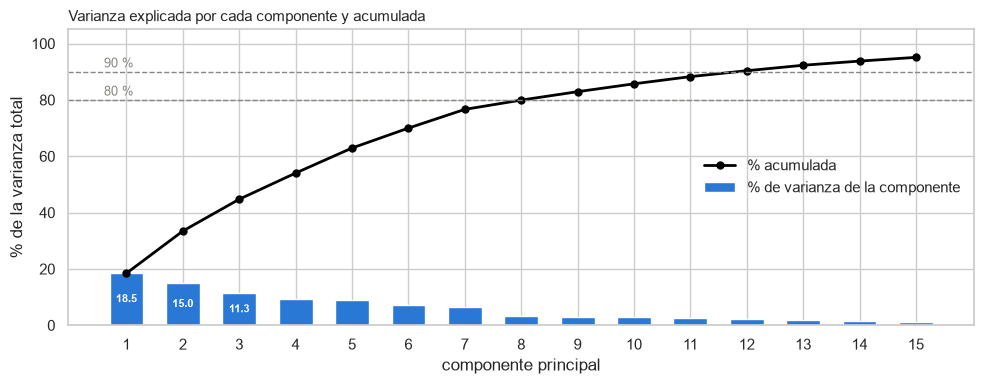

In [5]:
n = 15
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, n + 1), var_exp["% varianza"][:n], color=COLORES[0], width=0.6, label="% de varianza de la componente")
ax.plot(range(1, n + 1), var_exp["% acumulada"][:n], color="black", marker="o", markersize=5, linewidth=2,
        label="% acumulada")
for u in [80, 90]:
    ax.axhline(u, color=GRIS, linestyle="--", linewidth=1)
    ax.text(0.6, u + 1.5, f"{u} %", fontsize=9, color=GRIS)
for i in range(3):
    ax.text(i + 1, var_exp["% varianza"].iloc[i] / 2, f"{var_exp['% varianza'].iloc[i]:.1f}", ha="center", va="center",
            fontsize=8, color="white", fontweight="bold")
ax.set_xticks(range(1, n + 1))
ax.set_xlabel("componente principal")
ax.set_ylabel("% de la varianza total")
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="center right")
ax.set_title("Varianza explicada por cada componente y acumulada", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "06_varianza.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Lo que afirmamos en el texto de abajo
assert 30 < var_exp["% acumulada"]["PC2"] < 40 and 40 < var_exp["% acumulada"]["PC3"] < 50
assert n_para[80] == 9 and var_exp["% varianza"]["PC8"] < var_exp["% varianza"]["PC7"] / 1.5

Cómo se lee:

- **PC1 y PC2 juntas recogen un tercio de la variación** (33,5 %) y con PC3 llegamos al 45 %. Un gráfico 2D enseña, por tanto, solo una parte de cómo se diferencian los clientes: lo que no se ve en el dibujo no significa que no exista.
- La varianza se reparte bastante entre las 7 primeras componentes (de 18 % a 7 %), y **a partir de la 8.ª cae de golpe** (la mitad que la 7.ª). Hay unas 7 direcciones importantes en los datos y el resto aporta poco cada una, sobre todo las combinaciones de binarias.
- Para recoger el 80 % de la variación hacen falta 9 componentes. No hay una reducción "barata" a 2 o 3 dimensiones, y es otro motivo para no segmentar sobre PCA.

## 4. Qué significa cada componente: las cargas

La carga de una variable en una componente dice cuánto pesa y en qué sentido: positiva si la componente sube cuando sube la variable, negativa al revés. Miramos las 5 primeras componentes, que recogen el 63 % de la varianza.

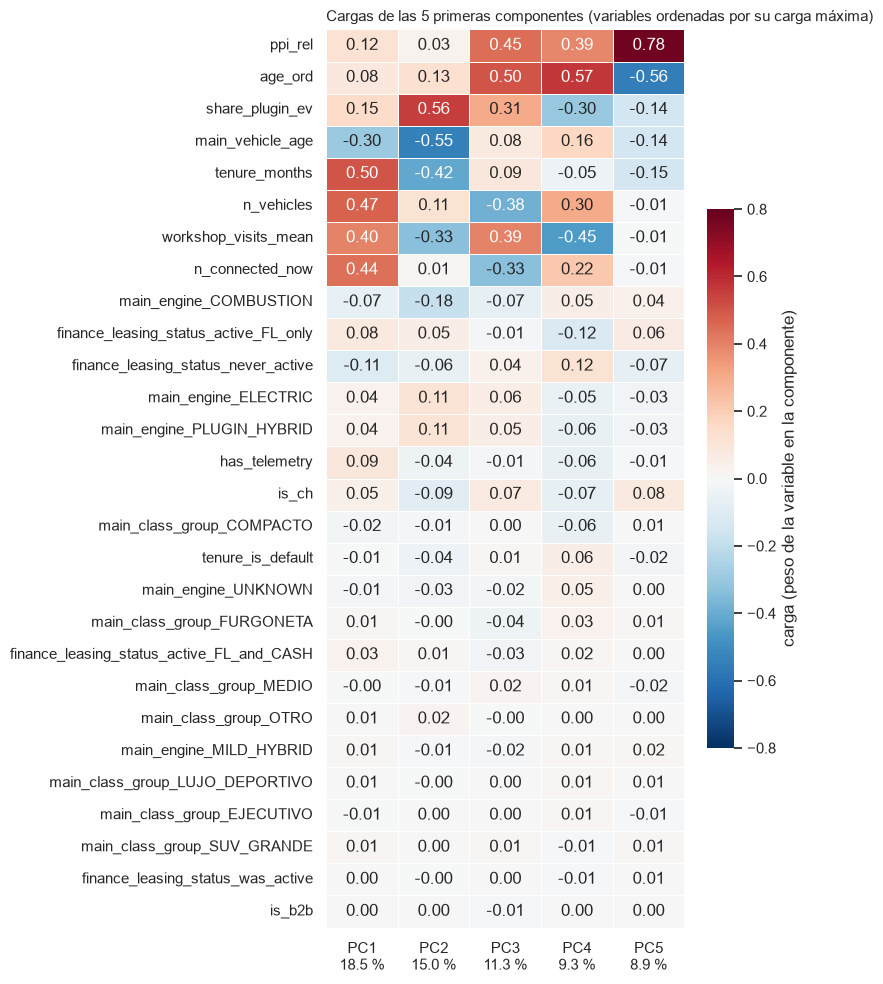

In [7]:
N_PC = 5
cargas = pd.DataFrame(pca.components_[:N_PC].T, index=nombres, columns=PCS[:N_PC])
orden = cargas.abs().max(axis=1).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(cargas.loc[orden], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.8, vmax=0.8,
            linewidths=0.5, cbar_kws={"label": "carga (peso de la variable en la componente)", "shrink": 0.6}, ax=ax)
ax.set_xticklabels([f"{pc}\n{var_exp.loc[pc, '% varianza']:.1f} %" for pc in PCS[:N_PC]])
ax.set_title("Cargas de las 5 primeras componentes (variables ordenadas por su carga máxima)", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "06_cargas.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
top = {}
for pc in PCS[:N_PC]:
    c = cargas[pc].reindex(cargas[pc].abs().sort_values(ascending=False).index)[:5]
    top[pc] = [f"{v} ({c[v]:+.2f})" for v in c.index]
pd.DataFrame(top, index=[f"{i + 1}.ª" for i in range(5)])

,PC1,PC2,PC3,PC4,PC5
1.ª,tenure_months (+0.50),share_plugin_ev (+0.56),age_ord (+0.50),age_ord (+0.57),ppi_rel (+0.78)
2.ª,n_vehicles (+0.47),main_vehicle_age (-0.55),ppi_rel (+0.45),workshop_visits_mean (-0.45),age_ord (-0.56)
3.ª,n_connected_now (+0.44),tenure_months (-0.42),workshop_visits_mean (+0.39),ppi_rel (+0.39),tenure_months (-0.15)
4.ª,workshop_visits_mean (+0.40),workshop_visits_mean (-0.33),n_vehicles (-0.38),share_plugin_ev (-0.30),main_vehicle_age (-0.14)
5.ª,main_vehicle_age (-0.30),main_engine_COMBUSTION (-0.18),n_connected_now (-0.33),n_vehicles (+0.30),share_plugin_ev (-0.14)


Para traducir las componentes a lenguaje de negocio ayuda ver también **dónde cae cada segmento** en ellas: la posición media de sus clientes en cada componente.

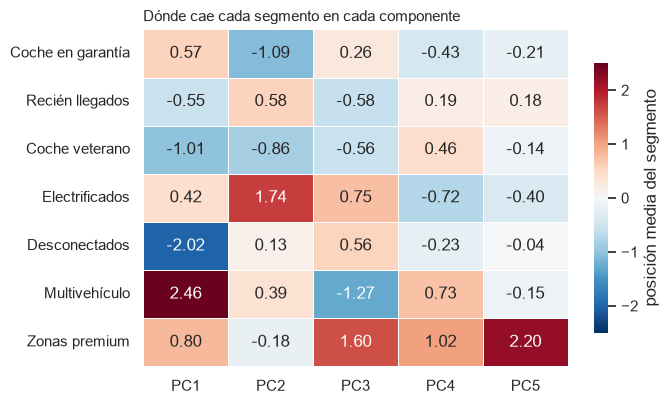

In [9]:
centros = pd.DataFrame(Z[:, :N_PC], columns=PCS[:N_PC]).groupby(seg).mean()
centros.index = SEG

fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(centros, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, linewidths=0.5,
            cbar_kws={"label": "posición media del segmento", "shrink": 0.8}, ax=ax)
ax.set_title("Dónde cae cada segmento en cada componente", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "06_segmentos_en_componentes.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# Lo que afirmamos en la interpretación de abajo (cargas y posiciones de los segmentos)
c = cargas
assert (c.loc[["tenure_months", "n_vehicles", "n_connected_now", "workshop_visits_mean"], "PC1"] > 0.35).all()
assert c.loc["main_vehicle_age", "PC1"] < 0
assert c.loc["share_plugin_ev", "PC2"] > 0.5 and c.loc["main_vehicle_age", "PC2"] < -0.5
assert c["PC3"].abs().nlargest(2).index.tolist() == ["age_ord", "ppi_rel"] and (c.loc[["age_ord", "ppi_rel"], "PC3"] > 0).all()
assert c["PC5"].abs().idxmax() == "ppi_rel"
assert centros["PC1"].idxmax() == "Multivehículo" and centros["PC1"].idxmin() == "Desconectados"
assert centros["PC2"].idxmax() == "Electrificados"
assert centros["PC3"].idxmax() == "Zonas premium"
# Las binarias y one-hot pesan poco en las 5 primeras componentes
assert cargas.drop(num).abs().max().max() < 0.3

**Interpretación de las componentes:**

| Componente | Varianza | Qué la sube (+) | Qué la baja (−) | En lenguaje de negocio | Segmentos que separa |
|---|---|---|---|---|---|
| **PC1** | 18,5 % | Antigüedad como cliente, nº de vehículos, vehículos conectados, visitas en garantía | Antigüedad del coche | **Intensidad de la relación con la marca**: cuánto tiempo, cuántos coches y cuánto contacto con el taller | Multivehículo (+) frente a Desconectados (−) |
| **PC2** | 15,0 % | % de coches enchufables o eléctricos | Antigüedad del coche y del cliente, visitas en garantía | **Electrificación y renovación**: clientes con coche nuevo y electrificado frente a coche veterano de combustión | Electrificados (+) frente a Coche en garantía y Coche veterano (−) |
| **PC3** | 11,3 % | Edad del cliente, riqueza de su zona (`ppi_rel`), visitas en garantía | Nº de vehículos y conectados | **Perfil personal**: cliente maduro, de zona acomodada y con un solo coche | Zonas premium (+) frente a Multivehículo (−) |
| **PC4** | 9,3 % | Edad del cliente, riqueza de la zona | Visitas en garantía, electrificación | Edad frente a uso del taller | — |
| **PC5** | 8,9 % | **Riqueza de la zona** (casi en exclusiva) | Edad del cliente | **Poder adquisitivo** de la zona, separado de la edad | Zonas premium |

Tres observaciones:

- **Las tres primeras componentes son tres ideas de negocio distintas** y fáciles de explicar: cuánta relación tiene el cliente con la marca, si ya está en el eléctrico o tiene un coche que renovar, y su perfil personal (edad y zona). Encaja con los nombres que pusimos a los segmentos en el reto 4.
- **Ninguna binaria ni one-hot pesa más de 0,3** en las 5 primeras componentes. La clase del coche, el motor exacto o el tipo de financiación aportan poco a la forma general de los datos: su efecto está repartido en muchas componentes pequeñas. Es la consecuencia de la escala que les dimos en el reto 2 (sección 2), no necesariamente de que sean poco importantes para el negocio.
- Los signos de las componentes son arbitrarios (PCA podría haber dado PC1 al revés). Lo que importa es qué variables van juntas y cuáles van en sentido contrario.

## 5. Los segmentos en 2D

Dibujamos la muestra de 20.000 clientes sobre las dos primeras componentes, cada uno con el color de su segmento. Los puntos van **en orden aleatorio** para que ningún segmento tape a los demás solo por dibujarse el último, y son semitransparentes para que se vea dónde hay más densidad. Las etiquetas marcan la posición media de cada segmento.

Al lado, el mismo dibujo con PC1 y PC3, porque, como hemos visto, hay un segmento (Zonas premium) que solo se separa en la PC3.

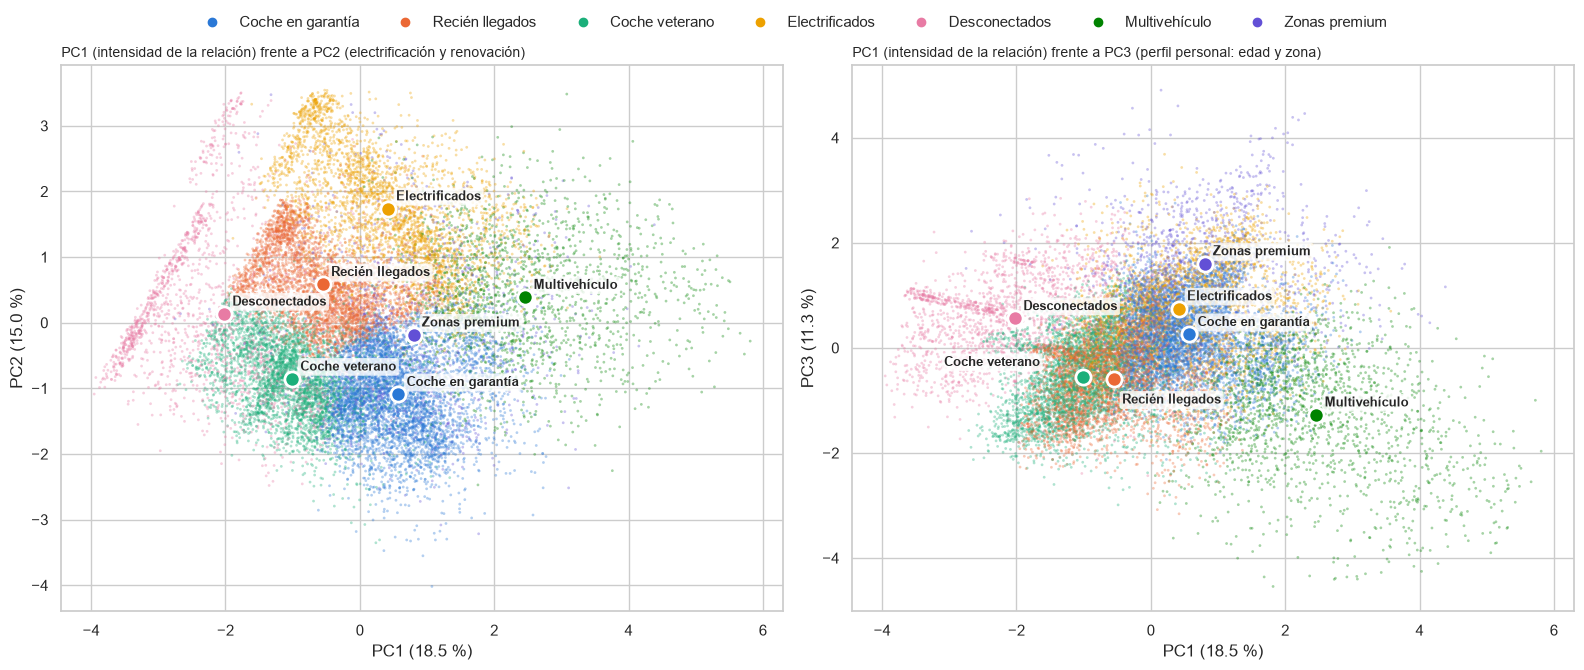

In [11]:
idx = clustering.sample_index(len(X))
orden_dibujo = np.random.default_rng(config.RANDOM_STATE).permutation(idx)  # orden aleatorio: nadie tapa a nadie
colores_puntos = np.array(COLORES)[seg[orden_dibujo]]
centros_3 = pd.DataFrame(Z[:, :3], columns=PCS[:3]).groupby(seg).mean()


def dispersion(ax, a, b, desplazar=None):
    ax.scatter(Z[orden_dibujo, a], Z[orden_dibujo, b], c=colores_puntos, s=4, alpha=0.35, linewidths=0)
    for i in range(K):
        x, y = centros_3.iloc[i, a], centros_3.iloc[i, b]
        ax.scatter(x, y, s=120, color=COLORES[i], edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(SEG[i], (x, y), xytext=(desplazar or {}).get(SEG[i], (6, 6)), textcoords="offset points", fontsize=9, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8), zorder=4)
    ax.set_xlabel(f"{PCS[a]} ({var_exp['% varianza'].iloc[a]:.1f} %)")
    ax.set_ylabel(f"{PCS[b]} ({var_exp['% varianza'].iloc[b]:.1f} %)")


fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
dispersion(axes[0], 0, 1)
axes[0].set_title("PC1 (intensidad de la relación) frente a PC2 (electrificación y renovación)", loc="left", fontsize=10)
dispersion(axes[1], 0, 2, desplazar={"Recién llegados": (6, -18), "Coche veterano": (-100, 8)})  # sus centros están muy juntos
axes[1].set_title("PC1 (intensidad de la relación) frente a PC3 (perfil personal: edad y zona)", loc="left", fontsize=10)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=COLORES[i], label=SEG[i]) for i in range(K)]
fig.legend(handles=handles, loc="upper center", ncol=K, frameon=False, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.savefig(FIG / "06_pca_2d.png", dpi=150, bbox_inches="tight")
plt.show()

Con 7 segmentos en un mismo dibujo es difícil ver dónde está cada uno, porque se tapan entre sí. Para valorar de verdad el solapamiento los separamos: un panel por segmento, con sus clientes en color y el resto de la base en gris de fondo.

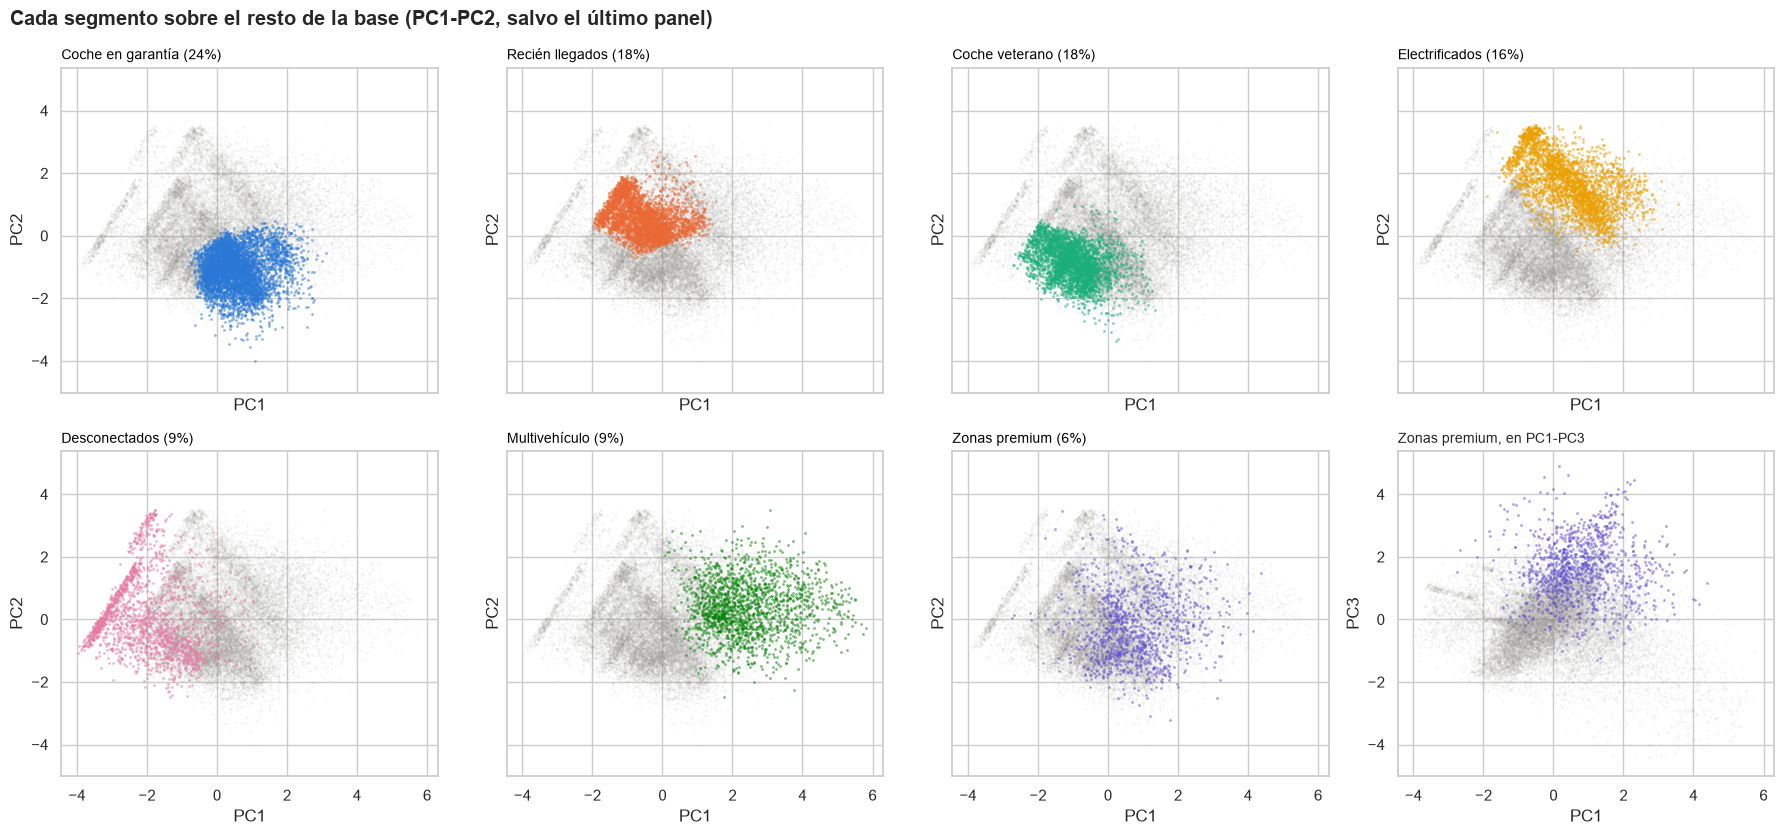

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.5), sharex=True, sharey=True)
for i, ax in enumerate(axes.flat[:K]):
    propio = orden_dibujo[seg[orden_dibujo] == i]
    ax.scatter(Z[orden_dibujo, 0], Z[orden_dibujo, 1], s=3, color=GRIS, alpha=0.08, linewidths=0)
    ax.scatter(Z[propio, 0], Z[propio, 1], s=4, color=COLORES[i], alpha=0.5, linewidths=0)
    ax.set_title(f"{SEG[i]} ({np.mean(seg == i):.0%})", loc="left", fontsize=10, color="black")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

# Último panel: Zonas premium en PC1-PC3, donde sí se separa
ax = axes.flat[K]
i = SEG.index("Zonas premium")
propio = orden_dibujo[seg[orden_dibujo] == i]
ax.scatter(Z[orden_dibujo, 0], Z[orden_dibujo, 2], s=3, color=GRIS, alpha=0.08, linewidths=0)
ax.scatter(Z[propio, 0], Z[propio, 2], s=4, color=COLORES[i], alpha=0.5, linewidths=0)
ax.set_title("Zonas premium, en PC1-PC3", loc="left", fontsize=10)
ax.set_xlabel("PC1")
ax.set_ylabel("PC3")
ax.tick_params(labelleft=True)
fig.suptitle("Cada segmento sobre el resto de la base (PC1-PC2, salvo el último panel)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "06_pca_por_segmento.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Los segmentos en 3D

Con las tres primeras componentes recogemos el 45 % de la varianza. Usamos matplotlib (plotly no está en el proyecto), con una muestra más pequeña (8.000 clientes) para que no se convierta en una nube opaca.

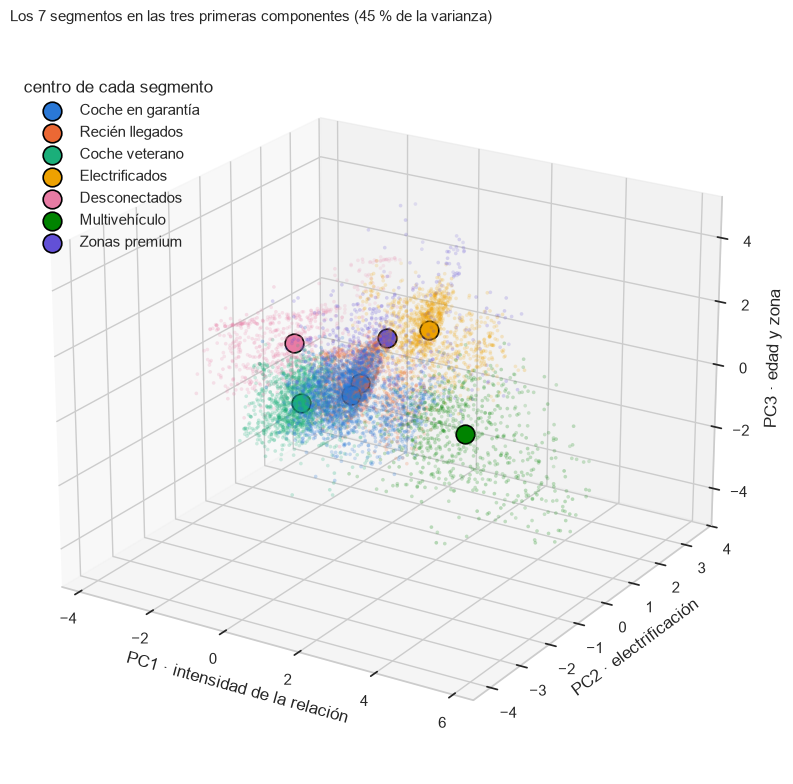

In [13]:
mini = orden_dibujo[:8_000]
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(Z[mini, 0], Z[mini, 1], Z[mini, 2], c=np.array(COLORES)[seg[mini]], s=7, alpha=0.55, linewidths=0)
for i in range(K):
    ax.scatter(*centros_3.iloc[i], s=180, color=COLORES[i], edgecolor="black", linewidth=1.2, depthshade=False,
               label=SEG[i])  # en 3D las etiquetas de texto se pisan: usamos leyenda
ax.set_xlabel("PC1 · intensidad de la relación")
ax.set_ylabel("PC2 · electrificación")
ax.set_zlabel("PC3 · edad y zona")
ax.view_init(elev=22, azim=-58)
ax.legend(title="centro de cada segmento", frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.95))
ax.set_title("Los 7 segmentos en las tres primeras componentes (45 % de la varianza)", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "06_pca_3d.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. ¿Cuánto enseña el dibujo? Medirlo, además de mirarlo

Mirar un gráfico es subjetivo, así que lo acompañamos de una medida: si nos quedamos solo con las primeras *n* componentes y asignamos cada cliente al **segmento cuyo centro tiene más cerca**, ¿cuántos caen en su propio segmento?

Hay que leer bien esta medida. **No mide si los segmentos están separados**, sino **cuánto del corte de K-Means se conserva al quedarnos con *n* componentes**. K-Means asigna a cada cliente, por definición, el centro más cercano en las 28 dimensiones, así que con todas las componentes el acierto es prácticamente del 100 %, haya grupos reales o no (lo comprobamos abajo). Lo que nos dice es **lo fiel que es un dibujo con *n* componentes** a la segmentación real.

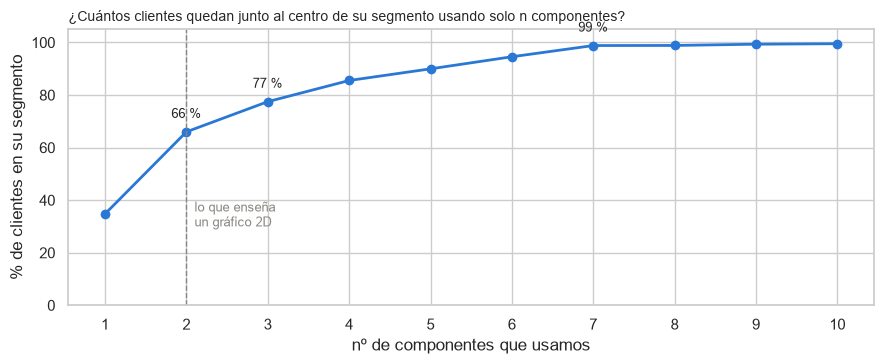

componentes,1,2,3,4,5,6,7,8,9,10
% en su propio segmento,34.7,66.0,77.5,85.5,90.0,94.6,98.8,98.9,99.3,99.5


In [14]:
def acierto(n, por_segmento=False):
    c = pd.DataFrame(Z[:, :n]).groupby(seg).mean().values
    cerca = ((Z[:, None, :n] - c[None]) ** 2).sum(axis=2).argmin(axis=1) == seg
    return pd.Series(cerca).groupby(seg).mean().values * 100 if por_segmento else cerca.mean() * 100


curva = pd.Series({n: acierto(n) for n in range(1, 11)}, name="% en su propio segmento")
curva.index.name = "componentes"

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(curva.index, curva.values, marker="o", color=COLORES[0], linewidth=2)
for n in [2, 3, 7]:
    ax.annotate(f"{curva[n]:.0f} %", (n, curva[n]), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9)
ax.axvline(2, color=GRIS, linestyle="--", linewidth=1)
ax.text(2.1, 30, "lo que enseña\nun gráfico 2D", fontsize=9, color=GRIS)
ax.set_xticks(curva.index)
ax.set_ylim(0, 105)
ax.set_xlabel("nº de componentes que usamos")
ax.set_ylabel("% de clientes en su segmento")
ax.set_title("¿Cuántos clientes quedan junto al centro de su segmento usando solo n componentes?", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "06_separacion.png", dpi=150, bbox_inches="tight")
plt.show()
curva.round(1).to_frame().T

In [15]:
por_segmento = pd.DataFrame({f"{n} componentes": acierto(n, por_segmento=True) for n in [2, 3, 7]}, index=SEG).round(1)
# Lo que afirmamos en el texto de abajo
assert 60 < curva[2] < 70 and curva[7] > 98
assert por_segmento["2 componentes"].idxmin() == "Zonas premium" and por_segmento.loc["Zonas premium", "2 componentes"] < 30
assert por_segmento.loc["Zonas premium", "3 componentes"] > 2 * por_segmento.loc["Zonas premium", "2 componentes"]
assert por_segmento.drop("Zonas premium")["2 componentes"].between(60, 75).all()
mejora = por_segmento["3 componentes"] - por_segmento["2 componentes"]
assert set(mejora.nlargest(3).index) == {"Zonas premium", "Recién llegados", "Multivehículo"}
por_segmento

,2 componentes,3 componentes,7 componentes
Coche en garantía,66.8,77.6,98.5
Recién llegados,67.3,83.4,98.3
Coche veterano,70.3,77.8,98.9
Electrificados,73.2,74.1,99.4
Desconectados,60.3,69.2,99.6
Multivehículo,73.2,88.7,98.6
Zonas premium,21.4,61.9,99.4


In [16]:
# Con las 28 componentes PCA solo gira los datos: el acierto es de casi el 100 % por construcción
# (no exacto porque K-Means se detiene cuando ya casi nadie cambia de grupo)
todas = acierto(pca.n_components_)
print(f"Con las {pca.n_components_} componentes: {todas:.2f} %")
assert todas > 99.9
# La separación real la mide el silhouette en el espacio completo (el mismo valor que en el reto 3)
from sklearn.metrics import silhouette_score
sil = silhouette_score(X[idx], seg[idx])
print(f"Silhouette de los segmentos en las 28 dimensiones: {sil:.3f}")
assert sil < 0.2

Con las 28 componentes: 99.96 %


Silhouette de los segmentos en las 28 dimensiones: 0.129


### Desconectados: dos partes muy distintas dentro del mismo segmento

En el panel de Desconectados se ven dos partes: una **franja propia en el extremo izquierdo** del gráfico (PC1 < −2,3, un corte que hacemos a ojo sobre el dibujo), que no comparte con ningún otro segmento, y el resto, que se mezcla con Coche veterano y Recién llegados. Comparamos las dos partes:

In [17]:
desc = SEG.index("Desconectados")
d = clientes[seg == desc]
franja = Z[seg == desc, 0] < -2.3
vars_desc = ["tenure_months", "n_vehicles", "main_vehicle_age", "workshop_visits_mean", "share_plugin_ev", "has_telemetry"]
partes = pd.DataFrame({"franja (PC1 < -2,3)": d[franja][vars_desc].mean(), "resto": d[~franja][vars_desc].mean()}).T
partes.insert(0, "% del segmento", [franja.mean() * 100, (~franja).mean() * 100])
partes["% con 0 meses de antigüedad"] = [(d[franja].tenure_months == 0).mean() * 100, (d[~franja].tenure_months == 0).mean() * 100]
assert 35 < partes.iloc[0, 0] < 50
assert partes.loc["franja (PC1 < -2,3)", "tenure_months"] < 10 < 20 < partes.loc["resto", "tenure_months"]
assert partes.loc["franja (PC1 < -2,3)", "workshop_visits_mean"] < 0.5 and partes.iloc[0]["% con 0 meses de antigüedad"] > 50
partes.round(2)

,% del segmento,tenure_months,n_vehicles,main_vehicle_age,workshop_visits_mean,share_plugin_ev,has_telemetry,% con 0 meses de antigüedad
"franja (PC1 < -2,3)",42.68,5.05,1.02,7.08,0.10,0.04,0.16,55.60
resto,57.32,26.53,1.46,4.56,1.99,0.24,0.53,10.55


La franja la forman clientes con **antigüedad casi nula** (más de la mitad, exactamente 0 meses), un único coche, sin visitas al taller y sin coche activo. Antes de interpretarla, miramos si ese "0 meses" es un valor real o un valor de registro, como pasaba con los 36 meses en el EDA:

In [18]:
base = clientes[clientes.tenure_months.between(0, 6)]
antig = base.groupby("tenure_months").agg(
    clientes=("tenure_months", "size"),
    sin_vehiculo_activo=("has_current_vehicle", lambda s: (1 - s.mean()) * 100),
    sin_visitas_taller=("workshop_visits_mean", lambda s: (s == 0).mean() * 100),
)
antig.index = antig.index.astype(int)
antig.columns = ["clientes", "% sin vehículo activo", "% sin visitas en garantía"]
assert antig.loc[0, "clientes"] > 2 * antig.loc[1, "clientes"]
assert antig.loc[0, "% sin vehículo activo"] > 2.5 * antig.loc[1, "% sin vehículo activo"]
antig.round(1)

,clientes,% sin vehículo activo,% sin visitas en garantía
tenure_months,,,
0,7254,65.2,97.9
1,3002,22.1,92.9
2,2706,10.0,89.2
3,2831,8.4,84.1
4,2686,6.8,80.3
5,2323,8.7,75.1
6,1153,18.0,71.6


**Los 0 meses no se comportan como un mes más.** Hay más del doble de clientes con 0 meses que con 1, y la mayoría no tienen ningún vehículo activo, frente a uno de cada cinco al mes siguiente. El diccionario define la antigüedad como "meses **desde su primera conexión a un coche**", así que nuestra hipótesis es que **el 0 marca a clientes que nunca han llegado a conectar un coche** (o cuya conexión no se ha registrado), más que a clientes recién llegados.

Para marketing la franja sigue siendo interesante, pero con esta lectura: **clientes registrados que no han activado nunca la relación** con su coche. Les encaja una **campaña de activación** (conectar el coche, primera revisión), distinta de la de **recuperación** que necesita el resto de Desconectados (clientes con unos 26 meses de recorrido que han dejado de tener coche activo). Antes de lanzarla habría que confirmar con Mercedes-Benz qué significa exactamente el 0. Y, como con el 36, convendría marcarlo en la tabla de clientes con un flag (`tenure_is_zero`) para que el modelo no lo trate como un mes más.

## 8. Valoración: ¿los clusters son visualmente separables?

**No del todo, y no solo por la proyección.** Cada segmento ocupa su propia zona, pero las fronteras se pisan. Lo resumimos así:

1. **Cinco segmentos tienen una zona propia en el plano PC1-PC2**, como se ve en los paneles por segmento: Electrificados arriba, Multivehículo a la derecha, Coche en garantía abajo en el centro, Coche veterano abajo a la izquierda y Recién llegados en el centro-izquierda. Pero en el plano 2D solo **unos 2 de cada 3 clientes** de cada segmento quedan junto a su propio centro (entre el 60 % y el 73 %): el resto está en la frontera con un vecino.
2. **Desconectados** tiene la parte más separada de todo el gráfico, la franja de clientes que nunca han conectado un coche, pero su otra parte se mezcla con los segmentos vecinos.
3. **Zonas premium no se ve en el plano PC1-PC2 y aparece al añadir la PC3.** Se define por la riqueza de su zona, que casi no pesa en PC1 ni PC2: en 2D solo uno de cada cinco de sus clientes queda junto a su centro, y con la PC3 sube a seis de cada diez.

Al añadir la tercera dimensión el dibujo se acerca bastante más a la segmentación real, sobre todo en **Zonas premium, Recién llegados y Multivehículo** (ver la tabla de la sección 7).

**¿Por qué se solapan?** Por dos motivos que hay que separar:

- **La proyección.** El dibujo 2D solo enseña un tercio de la variación (33,5 %). La información que define los segmentos está repartida en unas 7 componentes: con ellas, el 99 % de los clientes queda junto a su centro. Parte del solapamiento es, por tanto, un efecto de aplastar 7 dimensiones en 2.
- **Los propios datos.** Aun en las 28 dimensiones, los segmentos **no están bien separados**: el silhouette es de 0,13, y DBSCAN (notebook 05) no encontró grupos densos aislados. Los clientes forman un **continuo**, y los segmentos son cortes de ese continuo con perfiles distintos, no islas.

**¿Es un problema? No para el uso que les damos**, siempre que se tenga en cuenta. Lo que necesita marketing es que cada segmento tenga un perfil distinto y estable, y eso ya lo hemos comprobado (reto 4 y notebook 05). Pero hay que asumir que **los clientes de las fronteras se parecen a dos segmentos a la vez**. En campañas muy específicas conviene filtrar también por la variable concreta (por ejemplo, la antigüedad del coche) en lugar de fiarse solo de la etiqueta del segmento.

**Lo que aporta el PCA a la segmentación:**

- La base se ordena según **tres ideas de negocio**: la intensidad de la relación con la marca, la electrificación y renovación del coche, y el perfil personal del cliente (edad y zona). Son buenos ejes para presentar los segmentos a marketing.
- Ha sacado a la luz un **posible valor de registro en la antigüedad (0 meses)** que separa a los clientes que nunca han conectado un coche. Hay que verificarlo, y puede justificar un flag en la tabla de clientes.

## 9. Limitaciones

- **PCA no es la técnica ideal para datos mixtos.** 20 de las 28 columnas son 0/1, y PCA está pensado para variables continuas. La técnica específica sería un análisis factorial de datos mixtos (FAMD), que no está en scikit-learn. Usamos PCA sobre `X` a propósito, porque queríamos ver exactamente el espacio en el que trabajó K-Means, pero las componentes describen sobre todo las variables numéricas.
- **Que las binarias pesen poco es consecuencia de una decisión nuestra.** En el reto 2 decidimos no escalarlas, y por eso tienen menos varianza y pesan menos en PCA (y en K-Means). No quiere decir que la clase del coche o el motor sean poco importantes para el negocio, sino que en este modelo influyen poco. Darles más peso es una decisión de negocio posible para una siguiente versión.
- **Las líneas diagonales que se ven en los gráficos** (sobre todo a la izquierda) no son grupos de clientes. Las producen las variables con pocos valores posibles, como la edad en 6 tramos o el número de coches: los clientes que comparten esos valores caen alineados en la proyección.
- **El corte de la franja de Desconectados (PC1 < −2,3) es visual.** Sirve para describirla, pero si se quisiera usar en una campaña habría que definirla con una regla de negocio (por ejemplo, antigüedad 0 y sin coche activo).